# Downstream reconstruction

Evaluate masked protein reconstruction with the epoch-10 SOBER student on a real UPMC-HNC region from the saved **patient-held-out internal-validation partition**. We score 128 centers while retaining all 1,673 cells for normalization and neighborhood lookup. This small example illustrates the evaluation procedure; its scores do not reproduce the full-cohort manuscript results.

For the tested setup, use Python 3.12 and run from the repository root:
```bash
python -m pip install -r requirements-tutorials.txt -c constraints-tutorials.txt
python scripts/download_checkpoint.py
```

In [1]:
from pathlib import Path
import copy
import json
import sys
import platform
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sober/config.py").is_file())
sys.path.insert(0, str(ROOT))
from sober.checkpoint import load_checkpoint, file_sha256
from sober.data_loader import SpatialBiomarkerDataset

device = "cpu"
torch.set_num_threads(2)
model_info = json.loads((ROOT / "models/epoch10.json").read_text())
model, checkpoint = load_checkpoint(ROOT / "checkpoints/sober_epoch10.pth", device=device,
                                    expected_sha256=model_info["sha256"])
manifest = json.loads((ROOT / "examples/data/manifest.json").read_text())
example = manifest["downstream_examples"]
split_rows = {(r["study"], r["region"]): r for r in example["recorded_split"]["regions"]}
assert example["recorded_split"]["source_sha256"] == checkpoint["provenance"]["training_split_sha256"]
SEED, BATCH_SIZE = 42, 16
N_QUERY = 128
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"Epoch {checkpoint['epoch']} student | {device} | PyTorch {torch.__version__}")
from sober.evaluation import verify_example_files
from sober.evaluation import (
    RECONSTRUCTION_EXCLUSIONS, sample_neighborhoods, reconstruct, reconstruction_metrics,
)

Loaded 41 biomarkers from sober/assets/biomarker_sequences.csv
Loaded 1282 biomarker aliases
Building biomarker vocabulary using learnable method...
Processing 41 valid biomarkers (EMPTY ones filtered out)
Building learnable embeddings...


Epoch 10 student | cpu | PyTorch 2.15.0


## Load the validation region

The loader uses raw intensities and the checkpoint's marker aliases. Normalization is performed separately for each region and marker. The query region was selected by size from the saved validation partition, without inspecting predictions; [data provenance](../examples/data/README.md) records its source.

Each center keeps up to 100 nearest neighbors within 300 native coordinate units. The physical scale of this local export has not been verified.

In [2]:
query_record = example["query"]
verify_example_files(ROOT / "examples/data", [query_record])
assert split_rows[(query_record["study"], query_record["region"])]["partition"] == "validation"
data_config = copy.deepcopy(model.config)
data_config.use_cell_types = False
dataset = SpatialBiomarkerDataset(ROOT / "examples/downstream", data_config)
region = next(r for r in dataset.regions if (r["study_name"], r["region_name"]) == (query_record["study"], query_record["region"]))
assert set(region["biomarkers"]) <= set(checkpoint["biomarker_vocab"])
samples = sample_neighborhoods(region, model.config, n_cells=N_QUERY, seed=SEED)
print(f"{region['region_name']}: {region['num_cells']} cells; {len(samples)} evaluation centers")

Loaded cell-type version table: 22 studies from sober/assets/study_celltype_final.tsv
Loaded 1 regions; skipped 0 small regions
UPMC_c005_v001_r001_reg028: 1673 cells; 128 evaluation centers


## Predict hidden center markers

Masking follows the checkpoint: 80% of center markers and a random 20–80% count per neighbor, with mask-count bounds rounded down. The neighbor-mean baseline uses **the same visible neighbor entries** and excludes the center. When no neighbor value is visible, its prediction is missing rather than zero.

Only masked center entries are evaluated. All values are in normalized intensity units.

In [3]:
predictions = reconstruct(model, samples, batch_size=BATCH_SIZE, seed=SEED)
assert len(predictions) > 0 and np.isfinite(predictions[["observed", "sober"]]).all().all()
print(f"{len(predictions):,} masked center-marker entries")
predictions[["cell_id", "marker", "observed", "sober", "neighbor_mean", "n_visible_neighbors"]].head()

4,096 masked center-marker entries


,cell_id,marker,observed,sober,neighbor_mean,n_visible_neighbors
0,1109936,CD11c,1.743206,1.883957,1.716615,53
1,1109936,CD134,1.561671,1.152461,1.536585,46
2,1109936,CD14,0.350852,0.637852,0.916313,54
3,1109936,CD15,0.592953,0.422947,0.632724,57
4,1109936,CD16,2.096121,2.000260,1.795579,47


## Evaluate reconstruction

Apply the marker exclusions used in the saved main analysis to both methods. Pearson and Spearman correlations and MSE use finite observation–prediction pairs; `n` reports the number scored. Pooled correlations combine all retained entries, while the per-marker table evaluates each marker separately.

In [4]:
scored = predictions.loc[~predictions["marker"].isin(RECONSTRUCTION_EXCLUSIONS)].copy()
summary = reconstruction_metrics(scored)
per_marker = reconstruction_metrics(scored, groupby="marker")
print("Excluded markers present:", sorted(set(predictions["marker"]) & RECONSTRUCTION_EXCLUSIONS))
print(f"Excluded {len(predictions) - len(scored)} entries under the saved marker policy")
display(summary.round(4))
display(per_marker.head(10).round(4))

Excluded markers present: ['CD134', 'CD152', 'CD47', 'CD57', 'TMEM16A', 'p16']
Excluded 600 entries under the saved marker policy


,method,n,pearson_r,spearman_r,mse
0,sober,3496,0.8144,0.8318,0.3992
1,neighbor_mean,3496,0.7050,0.7097,0.5829


,marker,method,n,pearson_r,spearman_r,mse
0,CD117,sober,100,0.6427,0.6606,0.3840
1,CD117,neighbor_mean,100,0.5361,0.5828,0.4588
2,CD11b,sober,102,0.7153,0.7940,0.2263
3,CD11b,neighbor_mean,102,0.5502,0.6306,0.3320
4,CD11c,sober,111,0.7065,0.7083,0.3629
5,CD11c,neighbor_mean,111,0.5530,0.5443,0.5100
6,CD14,sober,99,0.7680,0.7104,0.3706
7,CD14,neighbor_mean,99,0.3706,0.5219,0.7212
8,CD15,sober,101,0.0538,0.2921,0.3060
9,CD15,neighbor_mean,101,-0.0131,0.0109,0.3040


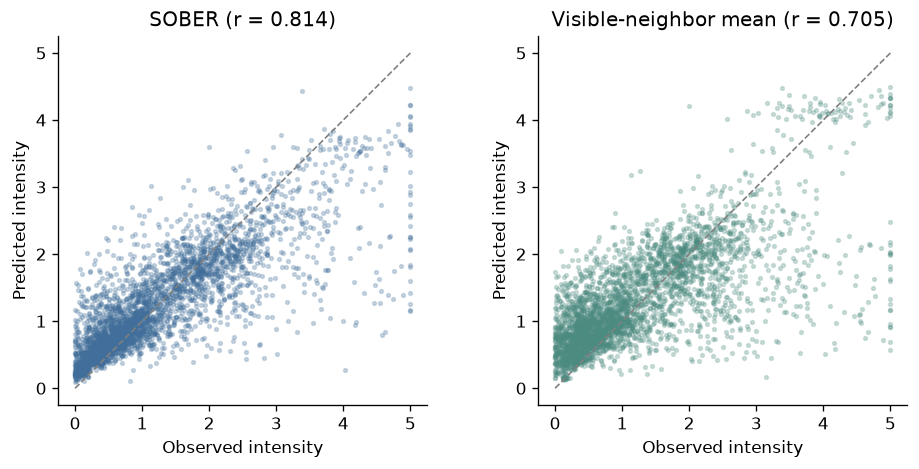

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8), layout="constrained")
for ax, method, title, color in zip(
    axes, ["sober", "neighbor_mean"], ["SOBER", "Visible-neighbor mean"], ["#416e9a", "#4c8b80"]
):
    valid = scored[["observed", method]].dropna()
    ax.scatter(valid["observed"], valid[method], s=5, alpha=0.25, color=color, rasterized=True)
    lo, hi = valid.to_numpy().min(), valid.to_numpy().max()
    ax.plot([lo, hi], [lo, hi], color="0.5", linewidth=1, linestyle="--")
    r = summary.set_index("method").loc[method, "pearson_r"]
    ax.set(xlabel="Observed intensity", ylabel="Predicted intensity", title=f"{title} (r = {r:.3f})")
    ax.set_aspect("equal", adjustable="box")
plt.show()

## Save the evaluation

The prediction table keeps cell IDs and all masked entries; the two metric tables use the stated marker exclusions. The JSON records the checkpoint, centers and evaluation settings.

In [6]:
output = ROOT / "checkpoints/reconstruction_demo"
output.mkdir(parents=True, exist_ok=True)
fig.savefig(output / "reconstruction.png", dpi=160, bbox_inches="tight")
predictions.to_csv(output / "predictions.csv", index=False)
summary.to_csv(output / "metrics.csv", index=False)
per_marker.to_csv(output / "per_marker_metrics.csv", index=False)
run = {
    "checkpoint_sha256": model_info["sha256"],
    "data_manifest_sha256": file_sha256(ROOT / "examples/data/manifest.json"),
    "environment": {"python": platform.python_version(), "device": device,
                    "packages": {p: version(p) for p in ("torch", "numpy", "pandas", "scipy", "scikit-learn")}},
    "weights": "student", "region": f"{region['study_name']}/{region['region_name']}",
    "partition": "internal_validation", "seed": SEED, "batch_size": BATCH_SIZE,
    "center_indices": [s["original_center_idx"] for s in samples],
    "requested_marker_exclusions": sorted(RECONSTRUCTION_EXCLUSIONS),
    "excluded_markers_present": sorted(set(predictions["marker"]) & RECONSTRUCTION_EXCLUSIONS),
    "masking": {k: v for k, v in checkpoint["config"].items() if "mask" in k},
}
(output / "evaluation.json").write_text(json.dumps(run, indent=2) + "\n")
print("Saved predictions.csv, metrics.csv, per_marker_metrics.csv and evaluation.json")

Saved predictions.csv, metrics.csv, per_marker_metrics.csv and evaluation.json
